# Smart Energy ML Model — Next-Hour Consumption Prediction
**Project:** IoT & AI-Powered Smart Energy Consumption Prediction and Control Platform

**Goal:** Predict the **average power for the next hour** from the last 3 hours and the time of day.

| Step | What happens |
|---|---|
| 1 | Load the UCI dataset |
| 2 | Clean the data (timestamps, numbers, **missing values**) |
| 3 | Convert minute readings → hourly averages |
| 4 | Create features (last 3 hours + time of day) |
| 5 | Split by time (train on older data, test on newer data) |
| 6 | Train 3 models: Naive baseline, Linear Regression, Random Forest |
| 7 | Compare MAE, RMSE, R² and plot results |
| 8 | Check the threshold alert |
| 9 | Save the best model for the backend |

### Two design choices that make this work with our hardware
1. **Only 3 hours of history needed** → the system can start predicting 3 hours after the ESP32 is switched on.
2. **Pattern-based (scale-free) prediction** → the UCI data is a whole house (~1 kW) but our prototype is one appliance (~0.06 kW). So every value is divided by the device's **typical power** (its average over the last 24 hours). The model learns *"next hour will be 1.3× the usual level"*, and the backend multiplies back by our device's own typical power. The same model then works for a house or a single bulb.

## Step 1 — Load the dataset
In Colab: upload `household_power_consumption.txt` using the 📁 Files panel on the left. If the file isn't there, the code downloads it from UCI automatically.

In [1]:
import os, zipfile, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "household_power_consumption.txt"

if not os.path.exists(DATA_PATH):
    import requests
    url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
    r = requests.get(url, timeout=120); r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        z.extract("household_power_consumption.txt")

df = pd.read_csv(DATA_PATH, sep=";", na_values=["?"], low_memory=False)
print("Raw shape:", df.shape)
print("\nMissing values per column (the '?' marks):")
print(df.isna().sum())
df.head()

Raw shape: (2075259, 9)

Missing values per column (the '?' marks):
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## Step 2 — Clean the data
| Problem | Fix |
|---|---|
| Date and Time are separate text columns | Combine into one `datetime` |
| Numbers stored as text | Convert to numeric |
| Bad timestamps / duplicate rows | Remove |
| **Missing readings (`?`)** | Short gaps (≤ 5 min) → filled by time interpolation. Long outages → left missing and handled in Step 3. We don't invent long stretches of data. |

In [2]:
df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"],
                                format="%d/%m/%Y %H:%M:%S", errors="coerce")

measurement_cols = ["Global_active_power", "Global_reactive_power", "Voltage",
                    "Global_intensity", "Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
df[measurement_cols] = df[measurement_cols].apply(pd.to_numeric, errors="coerce")

rows_before = len(df)
df = (df.dropna(subset=["datetime"])
        .sort_values("datetime")
        .drop_duplicates(subset=["datetime"])
        .set_index("datetime")
        .drop(columns=["Date", "Time"]))
print(f"Rows removed (bad timestamp/duplicate): {rows_before - len(df)}")

missing_before = df["Global_active_power"].isna().sum()
df[measurement_cols] = df[measurement_cols].interpolate(method="time", limit=5, limit_area="inside")
missing_after = df["Global_active_power"].isna().sum()

print(f"Missing power readings before: {missing_before:,} ({missing_before/len(df):.2%})")
print(f"Filled (short gaps):           {missing_before - missing_after:,}")
print(f"Still missing (long outages):  {missing_after:,}  → handled in Step 3")
print("Cleaned shape:", df.shape)
print("Date range:", df.index.min(), "→", df.index.max())
df.head()

Rows removed (bad timestamp/duplicate): 0


Missing power readings before: 25,979 (1.25%)
Filled (short gaps):           156
Still missing (long outages):  25,823  → handled in Step 3
Cleaned shape: (2075259, 7)
Date range: 2006-12-16 17:24:00 → 2010-11-26 21:02:00


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


## Step 3 — Convert to hourly data
Each hour = average of its minute readings. An hour is kept only if it has **at least 45 valid minutes**; hours inside long outages become missing and are dropped later.

Hourly rows: 34589 | hours dropped for missing data: 438
count    34151.000
mean         1.092
std          0.898
min          0.124
25%          0.342
50%          0.803
75%          1.579
max          6.561
Name: power_kw, dtype: float64


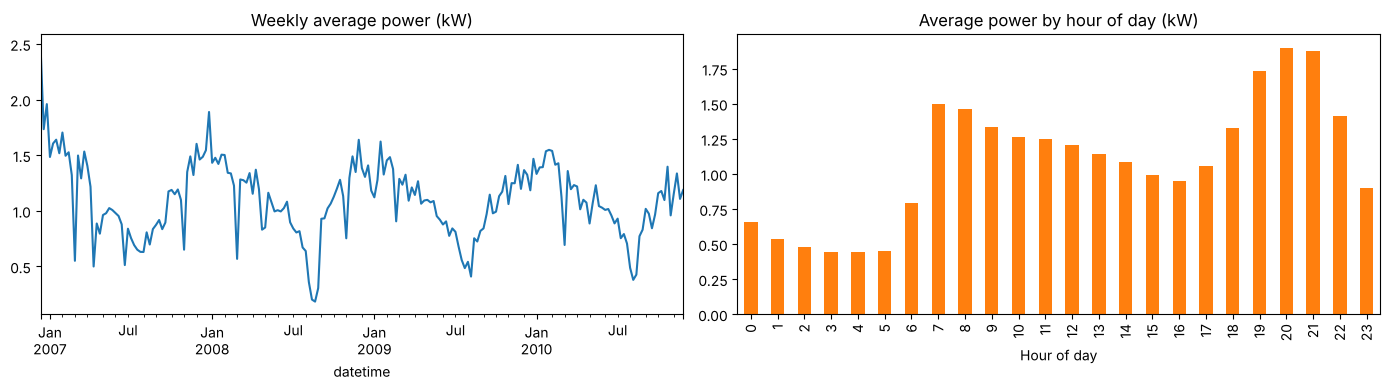

In [3]:
power = df["Global_active_power"]
hourly = power.resample("h").mean()
valid_minutes = power.resample("h").count()
hourly[valid_minutes < 45] = np.nan
hourly = hourly.to_frame("power_kw")

print("Hourly rows:", len(hourly), "| hours dropped for missing data:", hourly["power_kw"].isna().sum())
print(hourly["power_kw"].describe().round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
hourly["power_kw"].resample("W").mean().plot(ax=ax[0], title="Weekly average power (kW)")
hourly.groupby(hourly.index.hour)["power_kw"].mean().plot(kind="bar", ax=ax[1],
        title="Average power by hour of day (kW)", color="tab:orange")
ax[1].set_xlabel("Hour of day")
plt.tight_layout(); plt.show()

## Step 4 — Create features
**Typical power (`scale`)** = average of the last 24 hours. Every power value is divided by it.

| Feature | Meaning |
|---|---|
| `r0`, `r1`, `r2` | Current hour, 1 hour ago, 2 hours ago — each ÷ typical power |
| `hour_sin`, `hour_cos` | Time of day of the hour being predicted (circular, so 23:00 is next to 00:00) |
| `dayofweek`, `is_weekend` | Weekday patterns |

**Target:** `next hour ÷ typical power`. Prediction in kW = model output × typical power.

> The backend (`app.py`) computes exactly these features from ESP32 readings. If you change them here, change `make_features()` there too.

In [4]:
data = hourly.copy()
p = data["power_kw"]

data["scale"] = p.rolling(24, min_periods=24).mean()       # typical power, last 24 h
for k in [0, 1, 2]:
    data[f"r{k}"] = p.shift(k) / data["scale"]
data["target_kw"] = p.shift(-1)                            # next hour in kW
data["target"] = data["target_kw"] / data["scale"]         # next hour as a ratio

next_time = data.index + pd.Timedelta(hours=1)
data["hour_sin"] = np.sin(2 * np.pi * next_time.hour / 24)
data["hour_cos"] = np.cos(2 * np.pi * next_time.hour / 24)
data["dayofweek"] = next_time.dayofweek
data["is_weekend"] = (next_time.dayofweek >= 5).astype(int)

FEATURES = ["r0", "r1", "r2", "hour_sin", "hour_cos", "dayofweek", "is_weekend"]
data = data.dropna(subset=FEATURES + ["target", "scale"])
print("Model-ready rows:", len(data))
data[["power_kw", "scale"] + FEATURES + ["target"]].head()

Model-ready rows: 33791


,power_kw,scale,r0,r1,r2,hour_sin,hour_cos,dayofweek,is_weekend,target
datetime,,,,,,,,,,
2006-12-17 17:00:00,3.406767,2.465140,1.381977,1.349227,1.211047,-1.000000,-1.836970e-16,6,1,1.499752
2006-12-17 18:00:00,3.697100,2.467844,1.498109,1.380462,1.347748,-0.965926,2.588190e-01,6,1,1.178518
2006-12-17 19:00:00,2.908400,2.447351,1.188387,1.510654,1.392022,-0.866025,5.000000e-01,6,1,1.373526
2006-12-17 20:00:00,3.361500,2.451224,1.371356,1.186509,1.508267,-0.707107,7.071068e-01,6,1,1.240510
2006-12-17 21:00:00,3.040767,2.450569,1.240841,1.371722,1.186826,-0.500000,8.660254e-01,6,1,0.619448


## Step 5 — Chronological train/test split
We **never shuffle** time-series data. Train on the oldest 80%, test on the newest 20% — just like the real system, which predicts the future from the past.

In [5]:
split = int(len(data) * 0.8)
train, test = data.iloc[:split], data.iloc[split:]
X_train, y_train = train[FEATURES], train["target"]
X_test = test[FEATURES]
y_test_kw = test["target_kw"]          # we evaluate in real kW
scale_test = test["scale"].values

print(f"Train: {train.index.min():%Y-%m-%d} → {train.index.max():%Y-%m-%d}  ({len(train):,} hours)")
print(f"Test:  {test.index.min():%Y-%m-%d} → {test.index.max():%Y-%m-%d}  ({len(test):,} hours)")

Train: 2006-12-17 → 2010-02-05  (27,032 hours)
Test:  2010-02-05 → 2010-11-26  (6,759 hours)


## Step 6 — Train the models
| Model | Role |
|---|---|
| **Naive** (next hour = current hour) | Sanity check. A real model must beat this. |
| **Linear Regression** | Baseline ML model |
| **Random Forest Regressor** | Main candidate. Captures non-linear patterns |

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr = LinearRegression().fit(X_train, y_train)
rf = RandomForestRegressor(n_estimators=150, max_depth=12, min_samples_leaf=10,
                           n_jobs=-1, random_state=42).fit(X_train, y_train)

# Convert ratio predictions back to kW
preds = {
    "Naive (persistence)": test["power_kw"].values,
    "Linear Regression":  lr.predict(X_test) * scale_test,
    "Random Forest":      rf.predict(X_test) * scale_test,
}
print("Training complete.")

Training complete.


## Step 7 — Compare the models
- **MAE** — average error in kW (lower is better)
- **RMSE** — penalises big misses more (lower is better)
- **R²** — share of variation explained (closer to 1 is better)

In [7]:
rows = []
for name, yp in preds.items():
    rows.append({"Model": name,
                 "MAE (kW)": mean_absolute_error(y_test_kw, yp),
                 "RMSE (kW)": np.sqrt(mean_squared_error(y_test_kw, yp)),
                 "R²": r2_score(y_test_kw, yp)})
results = pd.DataFrame(rows).set_index("Model").round(4)
print(results)
best_name = results.drop(index="Naive (persistence)")["RMSE (kW)"].idxmin()
print(f"\nBest ML model by RMSE: {best_name}")

                     MAE (kW)  RMSE (kW)      R²
Model                                           
Naive (persistence)    0.3976     0.6033  0.3442
Linear Regression      0.3887     0.5435  0.4677
Random Forest          0.3466     0.4972  0.5545

Best ML model by RMSE: Random Forest


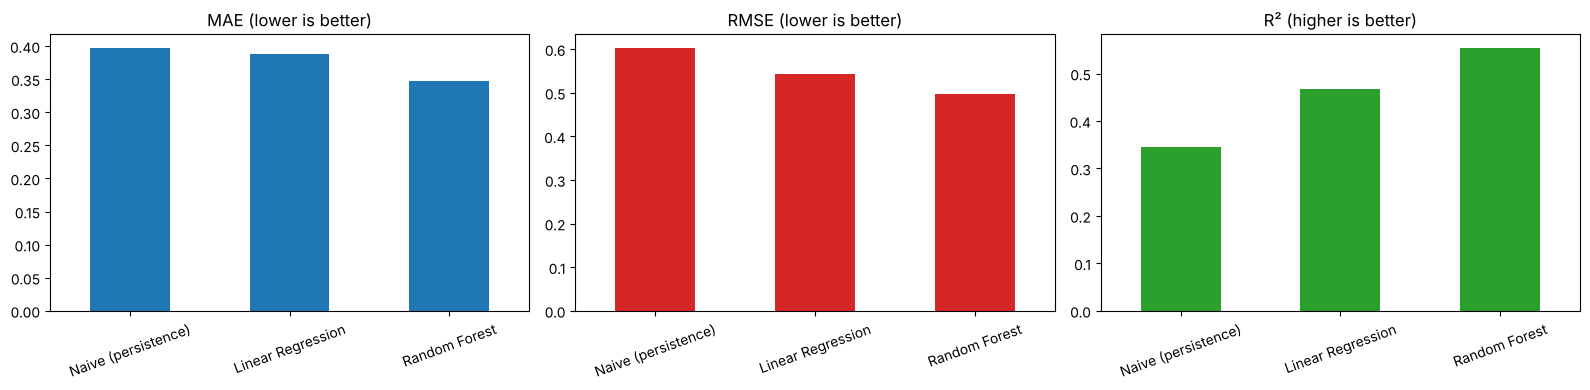

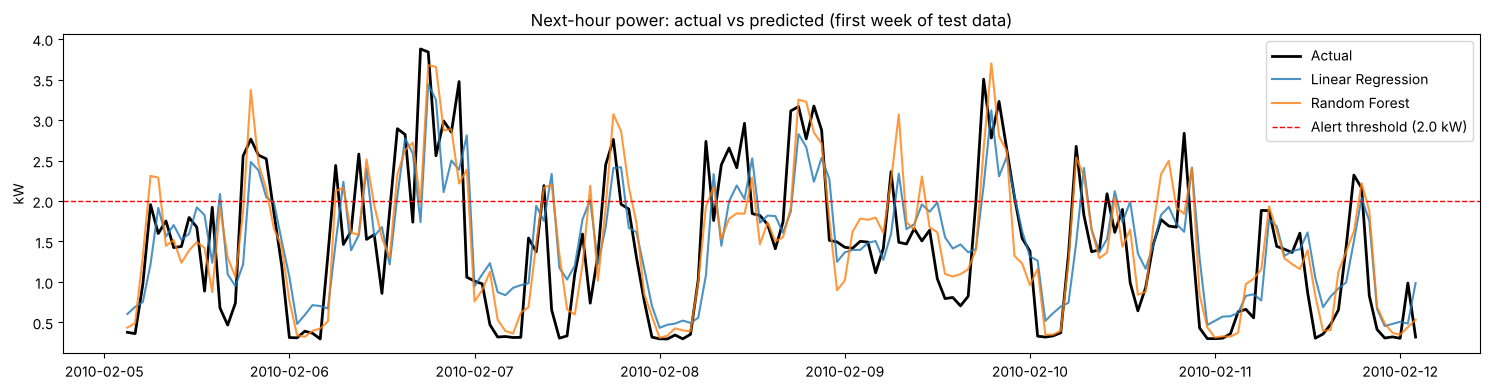

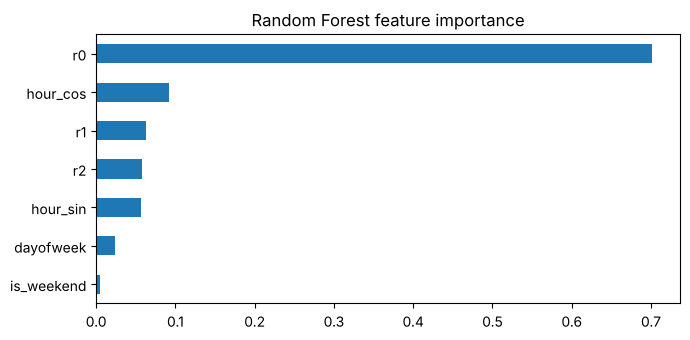

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
results["MAE (kW)"].plot(kind="bar", ax=axes[0], title="MAE (lower is better)", color="tab:blue")
results["RMSE (kW)"].plot(kind="bar", ax=axes[1], title="RMSE (lower is better)", color="tab:red")
results["R²"].plot(kind="bar", ax=axes[2], title="R² (higher is better)", color="tab:green")
for a in axes: a.tick_params(axis="x", rotation=20); a.set_xlabel("")
plt.tight_layout(); plt.show()

week = slice(0, 24 * 7)
plt.figure(figsize=(15, 4))
plt.plot(y_test_kw.index[week], y_test_kw.values[week], label="Actual", color="black", lw=2)
plt.plot(y_test_kw.index[week], preds["Linear Regression"][week], label="Linear Regression", alpha=0.8)
plt.plot(y_test_kw.index[week], preds["Random Forest"][week], label="Random Forest", alpha=0.8)
plt.axhline(2.0, color="red", ls="--", lw=1, label="Alert threshold (2.0 kW)")
plt.title("Next-hour power: actual vs predicted (first week of test data)")
plt.ylabel("kW"); plt.legend(); plt.tight_layout(); plt.show()

imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(7, 3.5), title="Random Forest feature importance")
plt.tight_layout(); plt.show()

## Step 8 — Threshold alert check
How well does each model flag hours that will exceed **2.0 kW** (a whole-house threshold)?
- **Precision** — when it raises an alert, how often is it right?
- **Recall** — of the real high-usage hours, how many did it catch?

In [9]:
from sklearn.metrics import precision_score, recall_score
THRESHOLD = 2.0
actual_high = (y_test_kw > THRESHOLD).astype(int)
alert_rows = []
for name, yp in preds.items():
    pred_high = (yp > THRESHOLD).astype(int)
    alert_rows.append({"Model": name,
                       "Precision": precision_score(actual_high, pred_high, zero_division=0),
                       "Recall": recall_score(actual_high, pred_high, zero_division=0),
                       "Alerts raised": int(pred_high.sum())})
print(f"Actual hours above {THRESHOLD} kW in test set: {actual_high.sum()} of {len(actual_high)}")
pd.DataFrame(alert_rows).set_index("Model").round(3)

Actual hours above 2.0 kW in test set: 724 of 6759


,Precision,Recall,Alerts raised
Model,,,
Naive (persistence),0.431,0.431,724
Linear Regression,0.506,0.307,439
Random Forest,0.549,0.423,557


## Step 9 — Save the model for the backend
Download `energy_model.pkl` from the 📁 Files panel (right-click → Download) and put it in the `backend` folder, next to `app.py`.

In [10]:
import joblib, sklearn
best_model = {"Linear Regression": lr, "Random Forest": rf}[best_name]
joblib.dump({"model": best_model, "model_name": best_name, "features": FEATURES,
             "scale_window_hours": 24, "sklearn_version": sklearn.__version__},
            "energy_model.pkl", compress=3)
print(f"Saved energy_model.pkl ({best_name}), {os.path.getsize('energy_model.pkl')/1e6:.1f} MB")

# Same model on a single 60 W bulb: it predicts in the bulb's own scale
bulb_typical_kw = 0.04                         # bulb on ~2/3 of the last 24 h
example = pd.DataFrame([{"r0": 1.5, "r1": 1.5, "r2": 1.0,   # on for the last 2 hours
                         "hour_sin": np.sin(2*np.pi*20/24), "hour_cos": np.cos(2*np.pi*20/24),
                         "dayofweek": 3, "is_weekend": 0}])[FEATURES]
print(f"Bulb example: predicted next hour = {best_model.predict(example)[0] * bulb_typical_kw * 1000:.0f} W")

Saved energy_model.pkl (Random Forest), 6.4 MB
Bulb example: predicted next hour = 63 W
